0.0 loss improvement over naive solution
0.0 constraint violation
0.0 loss improvement over naive solution
2.483837755346272e-16 constraint violation
0.0 loss improvement over naive solution
1.12113722928444e-16 constraint violation
0.0 loss improvement over naive solution
2.495231447213112e-16 constraint violation
0.0 loss improvement over naive solution
2.2206452925437466e-16 constraint violation
0.0 loss improvement over naive solution
8.01704901182173e-18 constraint violation
0.0 loss improvement over naive solution
3.1448640276145894e-16 constraint violation
0.0 loss improvement over naive solution
5.7681424568189845e-18 constraint violation
0.0 loss improvement over naive solution
2.4830831106075936e-16 constraint violation
2.220446049250313e-16 loss improvement over naive solution
2.220446049250313e-16 constraint violation


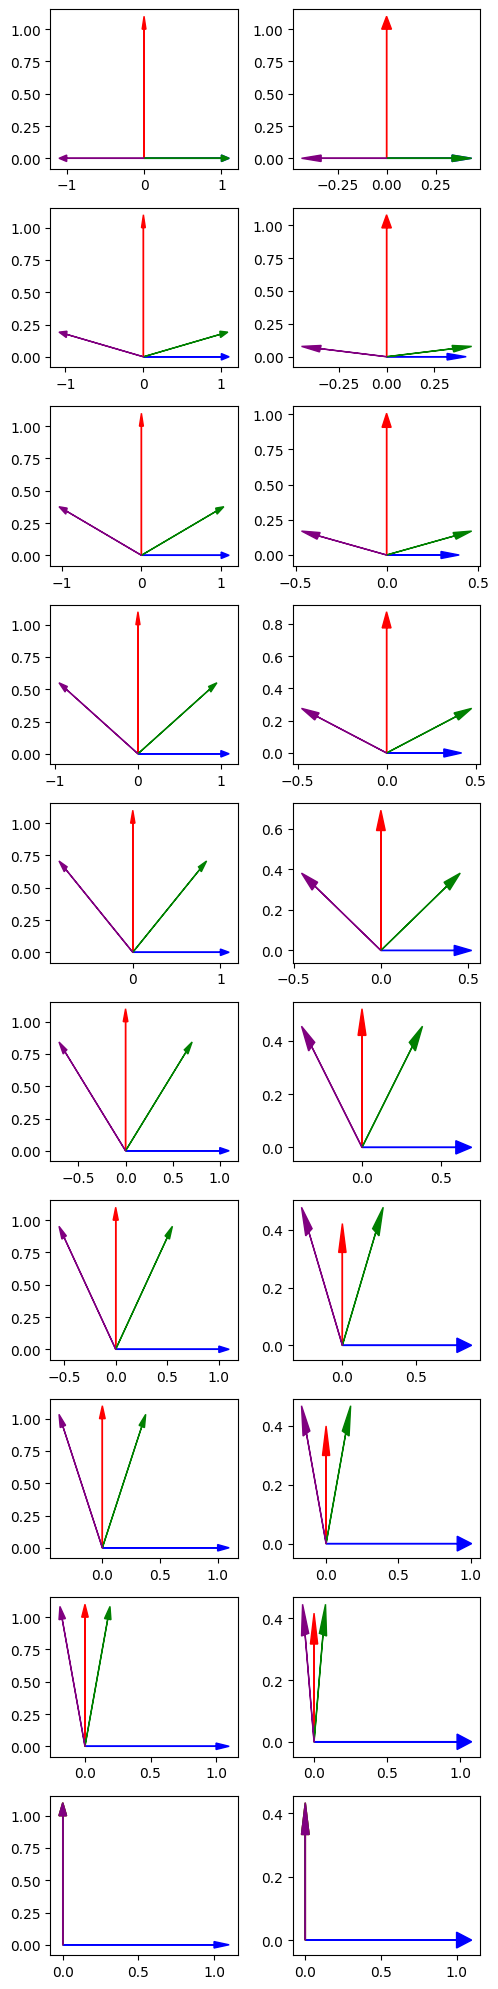

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    # Compute the residual R = X beta_hat - Y
    R = X @ beta_hat - Y  # Dimensions: (n x m)
    
    # Compute M = X X^T
    M = X @ X.T  # Dimensions: (n x n)
    
    # Solve M Lambda = R for Lambda (n x m)
    # Use least squares in case M is singular
    Lambda, residuals, rank, s = np.linalg.lstsq(M, R, rcond=None)
    
    # Compute beta_proj = beta_hat - X^T Lambda
    beta_proj = beta_hat - X.T @ Lambda  # Dimensions: (p x m)
    
    # Compute Y_proj = X beta_proj
    Y_proj = X @ beta_proj  # Dimensions: (n x m)
    
    return beta_proj, Y_proj


def group_lasso_norm(beta):  # beta_bp
    """Computes the group basis pursuit loss of the matrix beta"""
    output = np.linalg.norm(beta, axis=1).sum()
    return output


def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters = 2500,
    seed = 0,
    target = None,
):

    D,P = matrix.shape
    if target is None:
        target = np.identity(D)
    np.random.seed(seed)
    initialization = np.random.randn(P, D)
#     print(initialization)
#     beta = cp.Variable((P, D), value=initialization)  # Random initialization
    beta = cp.Variable((P,D))  # could initialize with lasso?
#     beta.value = np.asarray([[1.,0], [0,1.],[0,0],[0,0]])
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == target]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.}
    output = problem.solve(solver=cp.SCS, **scs_opts)
#     output = problem.solve(solver = cp.ECOS)
    if output is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0
    return beta_sparse

s = 1
D = 2

# Adjusting the layout to have two columns, one for data and one for betas
angles = np.linspace(0, np.pi / 2, 10)
betas = []
datas = []
# data = np.asarray([[1,0],[0,1],[0,0],[0,0]]).transpose()
for angle in angles[:]:
    data = np.asarray([[1,0],[0,1],[np.cos(angle),np.sin(angle)], [-np.cos(angle), np.sin(angle)]]).transpose()

    datas.append(data)
    beta_putative = group_basis_pursuit(data, eps = 1e-16, max_iters = 100000, seed = s*5, target = np.identity(2))
    beta, _ = project_onto_constraint(np.identity(D), data, beta_putative)
    betas.append(beta)
    print(2 - group_lasso_norm(beta), "loss improvement over naive solution")
    print(np.linalg.norm(np.identity(D) - data @ beta), "constraint violation")
    
    

fig, axes = plt.subplots(10, 2, figsize=(5, 20))

# Plot data on the left (first 10 subplots)
for i, (data,beta) in enumerate(zip(datas,betas)):
    axes[i,0].arrow(0, 0, data[0, 0], data[1,0], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,0].arrow(0, 0, data[0,1], data[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,0].arrow(0, 0, data[0,2], data[1,2], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,0].arrow(0, 0, data[0,3], data[1,3], head_width=0.05, head_length=0.1, fc='purple', ec='purple')
    
    axes[i,1].arrow(0, 0, beta[0, 0], beta[0,1], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,1].arrow(0, 0, beta[1, 0], beta[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,1].arrow(0, 0, beta[2,0], beta[2,1], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,1].arrow(0, 0, beta[3,0], beta[3,1], head_width=0.05, head_length=0.1, fc='purple', ec='purple')
    
plt.tight_layout()
plt.show()

We really want one number for the [0,1] reconstruction per feature? but that is what we have

one number overall per feature so we can't rotate... but that doesn't really make sense.  so we have this above.  negative amounts of a feature in one direction, and positive amounts in another.  why do they need to straddle?  cause when one is positive and the other negative they need to cancel out.  its the same as if one is mirrored kitty corner (multiplied by negative one in both coordinates).

Why not have two in the positive orthant? We can take the xs

-4.440892098500626e-16 loss improvement over naive solution
0.0 constraint violation
-3.1086244689504383e-15 loss improvement over naive solution
1.3614438709537616e-29 constraint violation
-1.7763568394002505e-15 loss improvement over naive solution
5.981602906443225e-32 constraint violation
0.0 loss improvement over naive solution
2.469326378005173e-32 constraint violation
0.0 loss improvement over naive solution
2.220446049250313e-16 constraint violation


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


2.220446049250313e-16 loss improvement over naive solution
2.2246122181845696e-16 constraint violation
0.0 loss improvement over naive solution
1.1250030593580853e-16 constraint violation
0.0 loss improvement over naive solution
5.076708195159686e-17 constraint violation
0.0 loss improvement over naive solution
9.94360544436028e-18 constraint violation
0.0 loss improvement over naive solution
1.7297565734544187e-32 constraint violation


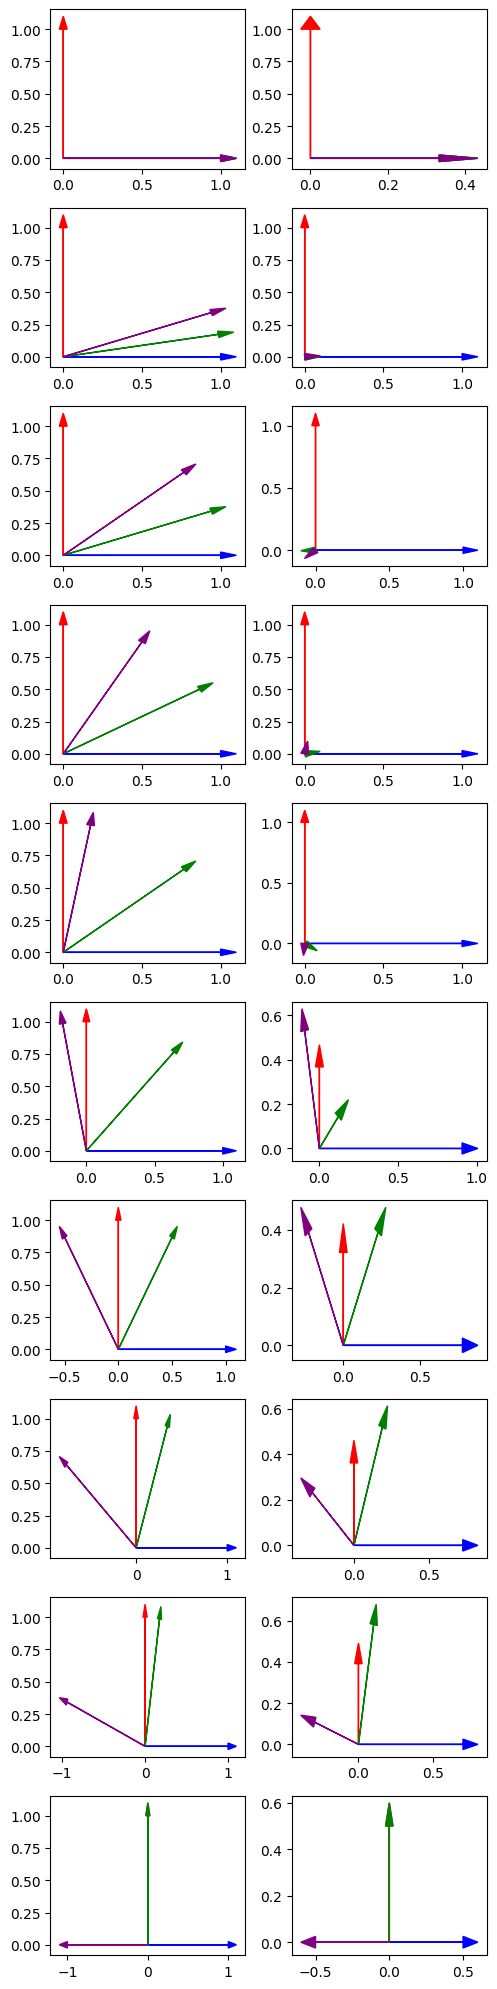

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    # Compute the residual R = X beta_hat - Y
    R = X @ beta_hat - Y  # Dimensions: (n x m)
    
    # Compute M = X X^T
    M = X @ X.T  # Dimensions: (n x n)
    
    # Solve M Lambda = R for Lambda (n x m)
    # Use least squares in case M is singular
    Lambda, residuals, rank, s = np.linalg.lstsq(M, R, rcond=None)
    
    # Compute beta_proj = beta_hat - X^T Lambda
    beta_proj = beta_hat - X.T @ Lambda  # Dimensions: (p x m)
    
    # Compute Y_proj = X beta_proj
    Y_proj = X @ beta_proj  # Dimensions: (n x m)
    
    return beta_proj, Y_proj


def group_lasso_norm(beta):  # beta_bp
    """Computes the group basis pursuit loss of the matrix beta"""
    output = np.linalg.norm(beta, axis=1).sum()
    return output


def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters = 2500,
    seed = 0,
    target = None,
):

    D,P = matrix.shape
    if target is None:
        target = np.identity(D)
    np.random.seed(seed)
    initialization = np.random.randn(P, D)
#     print(initialization)
#     beta = cp.Variable((P, D), value=initialization)  # Random initialization
    beta = cp.Variable((P,D))  # could initialize with lasso?
#     beta.value = np.asarray([[1.,0], [0,1.],[0,0],[0,0]])
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == target]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.}
    output = problem.solve(solver=cp.SCS, **scs_opts)
#     output = problem.solve(solver = cp.ECOS)
    if output is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0
    return beta_sparse

s = 1
D = 2

# Adjusting the layout to have two columns, one for data and one for betas
angles = np.linspace(0, np.pi / 2, 10)
betas = []
datas = []
# data = np.asarray([[1,0],[0,1],[0,0],[0,0]]).transpose()
for angle in angles[:]:
    data = np.asarray([[1,0],[0,1],[np.cos(angle),np.sin(angle)], [np.cos(2*angle), np.sin(2*angle)]]).transpose()

    datas.append(data)
    beta_putative = group_basis_pursuit(data, eps = 1e-16, max_iters = 100000, seed = s*5, target = np.identity(2))
    beta, _ = project_onto_constraint(np.identity(D), data, beta_putative)
    betas.append(beta)
    print(2 - group_lasso_norm(beta), "loss improvement over naive solution")
    print(np.linalg.norm(np.identity(D) - data @ beta), "constraint violation")
    
    

fig, axes = plt.subplots(10, 2, figsize=(5, 20))

# Plot data on the left (first 10 subplots)
for i, (data,beta) in enumerate(zip(datas,betas)):
    axes[i,0].arrow(0, 0, data[0, 0], data[1,0], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,0].arrow(0, 0, data[0,1], data[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,0].arrow(0, 0, data[0,2], data[1,2], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,0].arrow(0, 0, data[0,3], data[1,3], head_width=0.05, head_length=0.1, fc='purple', ec='purple')
    
    axes[i,1].arrow(0, 0, beta[0, 0], beta[0,1], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,1].arrow(0, 0, beta[1, 0], beta[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,1].arrow(0, 0, beta[2,0], beta[2,1], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,1].arrow(0, 0, beta[3,0], beta[3,1], head_width=0.05, head_length=0.1, fc='purple', ec='purple')
    
plt.tight_layout()
plt.show()

0.0 loss improvement over naive solution
0.0 constraint violation
0.0 loss improvement over naive solution
1.0479169822864547e-30 constraint violation
0.0 loss improvement over naive solution
1.4049721573412827e-32 constraint violation
0.0 loss improvement over naive solution
2.238059870934711e-32 constraint violation
-1.4210854715202004e-14 loss improvement over naive solution
6.8278533467543125e-28 constraint violation
0.0 loss improvement over naive solution
8.03128173036054e-32 constraint violation
-5.240252676230739e-14 loss improvement over naive solution
2.050156947299306e-28 constraint violation
-6.217248937900877e-15 loss improvement over naive solution
1.1699146565392551e-29 constraint violation
0.0 loss improvement over naive solution
2.4696967384027845e-31 constraint violation
0.0 loss improvement over naive solution
1.6993766692246567e-33 constraint violation


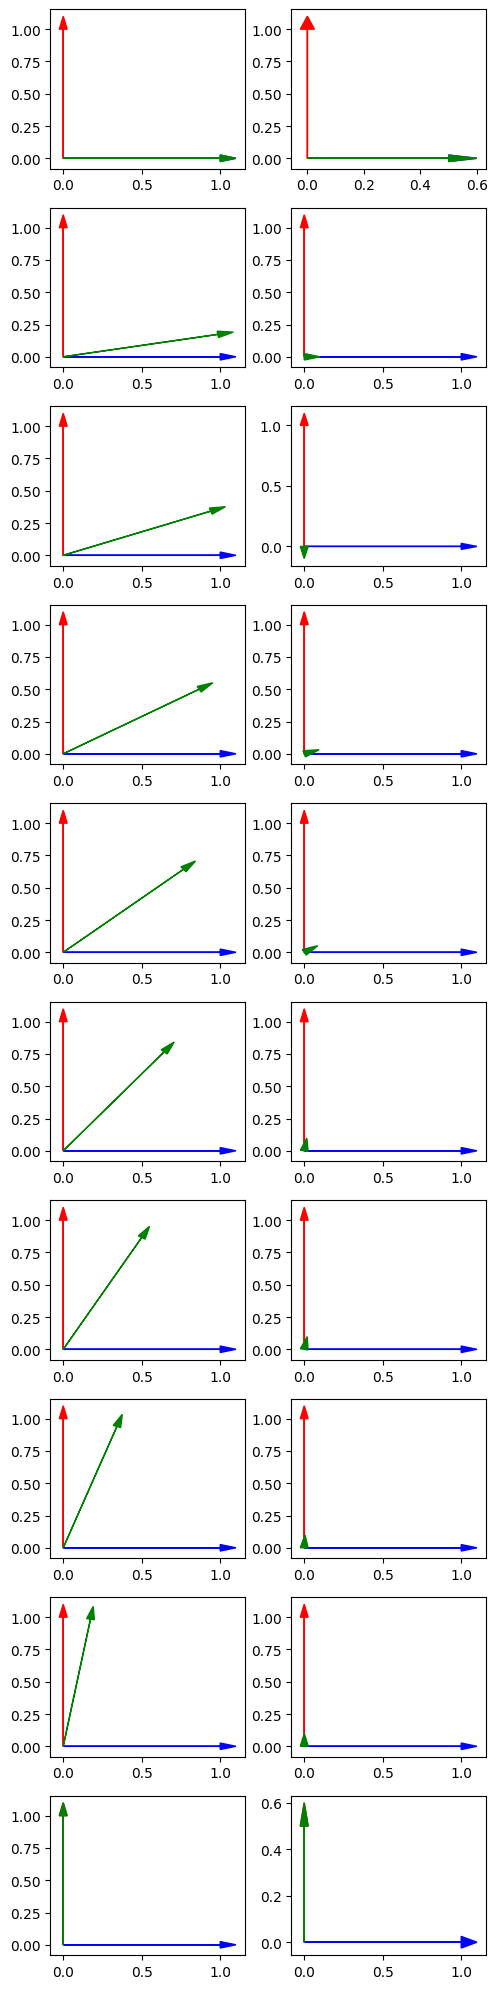

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    # Compute the residual R = X beta_hat - Y
    R = X @ beta_hat - Y  # Dimensions: (n x m)
    
    # Compute M = X X^T
    M = X @ X.T  # Dimensions: (n x n)
    
    # Solve M Lambda = R for Lambda (n x m)
    # Use least squares in case M is singular
    Lambda, residuals, rank, s = np.linalg.lstsq(M, R, rcond=None)
    
    # Compute beta_proj = beta_hat - X^T Lambda
    beta_proj = beta_hat - X.T @ Lambda  # Dimensions: (p x m)
    
    # Compute Y_proj = X beta_proj
    Y_proj = X @ beta_proj  # Dimensions: (n x m)
    
    return beta_proj, Y_proj


def group_lasso_norm(beta):  # beta_bp
    """Computes the group basis pursuit loss of the matrix beta"""
    output = np.linalg.norm(beta, axis=1).sum()
    return output


def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters = 2500,
    seed = 0,
    target = None,
):

    D,P = matrix.shape
    if target is None:
        target = np.identity(D)
    np.random.seed(seed)
    initialization = np.random.randn(P, D)
#     print(initialization)
#     beta = cp.Variable((P, D), value=initialization)  # Random initialization
    beta = cp.Variable((P,D))  # could initialize with lasso?
#     beta.value = np.asarray([[1.,0], [0,1.],[0,0],[0,0]])
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == target]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.}
    output = problem.solve(solver=cp.SCS, **scs_opts)
#     output = problem.solve(solver = cp.ECOS)
    if output is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0
    return beta_sparse

s = 1
D = 2

# Adjusting the layout to have two columns, one for data and one for betas
angles = np.linspace(0, np.pi / 2, 10)
betas = []
datas = []
# data = np.asarray([[1,0],[0,1],[0,0],[0,0]]).transpose()
for angle in angles[:]:
    data = np.asarray([[1,0],[0,1],[np.cos(angle),np.sin(angle)], [np.cos(2*angle), np.sin(2*angle)]]).transpose()[:,[0,1,2]]

    datas.append(data)
    beta_putative = group_basis_pursuit(data, eps = 1e-16, max_iters = 100000, seed = s*5, target = np.identity(2))
    beta, _ = project_onto_constraint(np.identity(D), data, beta_putative)
    betas.append(beta)
    print(2 - group_lasso_norm(beta), "loss improvement over naive solution")
    print(np.linalg.norm(np.identity(D) - data @ beta), "constraint violation")
    
    

fig, axes = plt.subplots(10, 2, figsize=(5, 20))

# Plot data on the left (first 10 subplots)
for i, (data,beta) in enumerate(zip(datas,betas)):
    axes[i,0].arrow(0, 0, data[0, 0], data[1,0], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,0].arrow(0, 0, data[0,1], data[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,0].arrow(0, 0, data[0,2], data[1,2], head_width=0.05, head_length=0.1, fc='green', ec='green')
    # axes[i,0].arrow(0, 0, data[0,3], data[1,3], head_width=0.05, head_length=0.1, fc='purple', ec='purple')
    
    axes[i,1].arrow(0, 0, beta[0, 0], beta[0,1], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,1].arrow(0, 0, beta[1, 0], beta[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,1].arrow(0, 0, beta[2,0], beta[2,1], head_width=0.05, head_length=0.1, fc='green', ec='green')
    # axes[i,1].arrow(0, 0, beta[3,0], beta[3,1], head_width=0.05, head_length=0.1, fc='purple', ec='purple')
    
plt.tight_layout()
plt.show()

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    # Compute the residual R = X beta_hat - Y
    R = X @ beta_hat - Y  # Dimensions: (n x m)
    
    # Compute M = X X^T
    M = X @ X.T  # Dimensions: (n x n)
    
    # Solve M Lambda = R for Lambda (n x m)
    # Use least squares in case M is singular
    Lambda, residuals, rank, s = np.linalg.lstsq(M, R, rcond=None)
    
    # Compute beta_proj = beta_hat - X^T Lambda
    beta_proj = beta_hat - X.T @ Lambda  # Dimensions: (p x m)
    
    # Compute Y_proj = X beta_proj
    Y_proj = X @ beta_proj  # Dimensions: (n x m)
    
    return beta_proj, Y_proj


def group_lasso_norm(beta):  # beta_bp
    """Computes the group basis pursuit loss of the matrix beta"""
    output = np.linalg.norm(beta, axis=1).sum()
    return output


def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters = 2500,
    seed = 0,
    target = None,
):

    D,P = matrix.shape
    if target is None:
        target = np.identity(D)
    np.random.seed(seed)
    initialization = np.random.randn(P, D)
#     print(initialization)
#     beta = cp.Variable((P, D), value=initialization)  # Random initialization
    beta = cp.Variable((P,D))  # could initialize with lasso?
#     beta.value = np.asarray([[1.,0], [0,1.],[0,0],[0,0]])
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == target]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.}
    output = problem.solve(solver=cp.SCS, **scs_opts)
#     output = problem.solve(solver = cp.ECOS)
    if output is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0
    return beta_sparse

s = 1
D = 2

# Adjusting the layout to have two columns, one for data and one for betas
# angles = np.linspace(np.pi / 12, np.pi / 2, 10)
angles = np.linspace(1e-10, np.pi / 3, 10)
betas = []
datas = []
# data = np.asarray([[1,0],[0,1],[0,0],[0,0]]).transpose()
for angle in angles[:]:
    data = np.asarray([[1,0],[np.cos(angle),np.sin(angle)], [-np.cos(angle), np.sin(angle)]]).transpose()

    datas.append(data)
    beta_putative = group_basis_pursuit(data, eps = 1e-16, max_iters = 100000, seed = s*5, target = np.identity(2))
    beta, _ = project_onto_constraint(np.identity(D), data, beta_putative)
    betas.append(beta)
    print('\n')
    print('angle', angle)
    print(group_lasso_norm(beta), "loss")
    print(np.linalg.norm(beta, axis = 1))
    print(np.linalg.norm(np.identity(D) - data @ beta), "constraint violation")
    
    

fig, axes = plt.subplots(10, 2, figsize=(5, 20))

# Plot data on the left (first 10 subplots)
for i, (data,beta) in enumerate(zip(datas,betas)):
    axes[i,0].arrow(0, 0, data[0, 0], data[1,0], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,0].arrow(0, 0, data[0,1], data[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,0].arrow(0, 0, data[0,2], data[1,2], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,0].set_xlim([-1.5,1.5])
    axes[i,0].set_ylim([-1.5,1.5])
    axes[i,1].arrow(0, 0, beta[0, 0], beta[0,1], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,1].arrow(0, 0, beta[1, 0], beta[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,1].arrow(0, 0, beta[2,0], beta[2,1], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,0].set_xlim([-1.5,1.5])
    axes[i,0].set_ylim([-1.5,1.5])
plt.tight_layout()
plt.show()

ValueError: No solution found

In [44]:
datas

[array([[ 1.       ,  0.5      , -0.5      ],
        [ 0.       ,  0.8660254,  0.8660254]])]

In [45]:
betas

[array([[ 6.66666667e-01,  1.98047023e-14],
        [ 3.33333333e-01,  5.77350269e-01],
        [-3.33333333e-01,  5.77350269e-01]])]

In [39]:
np.linalg.norm(betas[0], axis = 1)

array([0.66666667, 0.66666667, 0.66666667])



angle 0.7853981633974483
2.0 loss
[9.71590741e-15 1.00000000e+00 1.00000000e+00]
7.949437601634924e-17 constraint violation


angle 1.1780972450961724
2.0 loss
[0.82842712 0.58578644 0.58578644]
3.857366774783392e-17 constraint violation


angle 1.5707963267948966
2.0 loss
[1.  0.5 0.5]
2.0262863003818325e-33 constraint violation


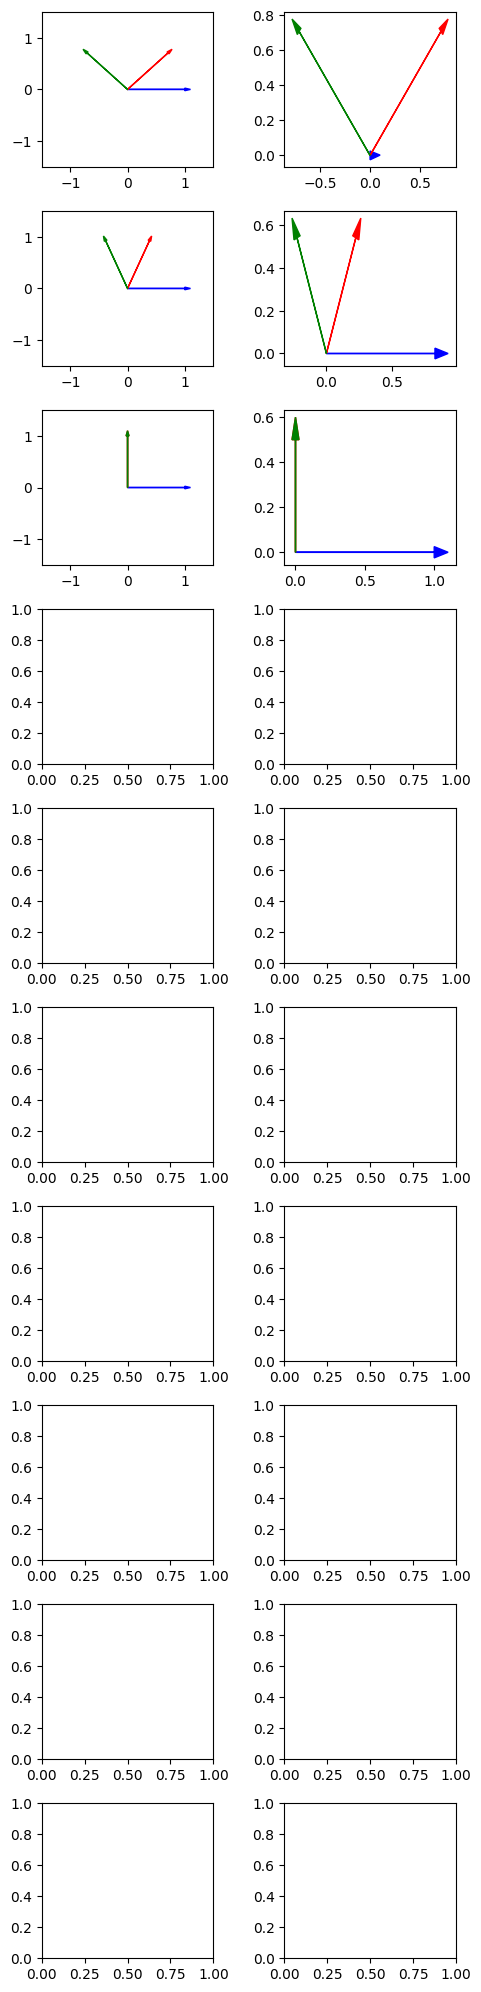

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    # Compute the residual R = X beta_hat - Y
    R = X @ beta_hat - Y  # Dimensions: (n x m)
    
    # Compute M = X X^T
    M = X @ X.T  # Dimensions: (n x n)
    
    # Solve M Lambda = R for Lambda (n x m)
    # Use least squares in case M is singular
    Lambda, residuals, rank, s = np.linalg.lstsq(M, R, rcond=None)
    
    # Compute beta_proj = beta_hat - X^T Lambda
    beta_proj = beta_hat - X.T @ Lambda  # Dimensions: (p x m)
    
    # Compute Y_proj = X beta_proj
    Y_proj = X @ beta_proj  # Dimensions: (n x m)
    
    return beta_proj, Y_proj


def group_lasso_norm(beta):  # beta_bp
    """Computes the group basis pursuit loss of the matrix beta"""
    output = np.linalg.norm(beta, axis=1).sum()
    return output


def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters = 2500,
    seed = 0,
    target = None,
):

    D,P = matrix.shape
    if target is None:
        target = np.identity(D)
    np.random.seed(seed)
    initialization = np.random.randn(P, D)
#     print(initialization)
#     beta = cp.Variable((P, D), value=initialization)  # Random initialization
    beta = cp.Variable((P,D))  # could initialize with lasso?
#     beta.value = np.asarray([[1.,0], [0,1.],[0,0],[0,0]])
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == target]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.}
    output = problem.solve(solver=cp.SCS, **scs_opts)
#     output = problem.solve(solver = cp.ECOS)
    if output is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0
    return beta_sparse

s = 1
D = 2

# Adjusting the layout to have two columns, one for data and one for betas
# angles = np.linspace(np.pi / 12, np.pi / 2, 10)
angles = np.linspace(np.pi / 4, np.pi /2 , 3)
betas = []
datas = []
# data = np.asarray([[1,0],[0,1],[0,0],[0,0]]).transpose()
for angle in angles[:]:
    data = np.asarray([[1,0],[np.cos(angle),np.sin(angle)], [-np.cos(angle), np.sin(angle)]]).transpose()

    datas.append(data)
    beta_putative = group_basis_pursuit(data, eps = 1e-16, max_iters = 100000, seed = s*5, target = np.identity(2))
    beta, _ = project_onto_constraint(np.identity(D), data, beta_putative)
    betas.append(beta)
    print('\n')
    print('angle', angle)
    print(group_lasso_norm(beta), "loss")
    print(np.linalg.norm(beta, axis = 1))
    print(np.linalg.norm(np.identity(D) - data @ beta), "constraint violation")
    
    

fig, axes = plt.subplots(10, 2, figsize=(5, 20))

# Plot data on the left (first 10 subplots)
for i, (data,beta) in enumerate(zip(datas,betas)):
    axes[i,0].arrow(0, 0, data[0, 0], data[1,0], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,0].arrow(0, 0, data[0,1], data[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,0].arrow(0, 0, data[0,2], data[1,2], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,0].set_xlim([-1.5,1.5])
    axes[i,0].set_ylim([-1.5,1.5])
    axes[i,1].arrow(0, 0, beta[0, 0], beta[0,1], head_width=0.05, head_length=0.1, fc='blue', ec='blue')
    axes[i,1].arrow(0, 0, beta[1, 0], beta[1,1], head_width=0.05, head_length=0.1, fc='red', ec='red')    
    axes[i,1].arrow(0, 0, beta[2,0], beta[2,1], head_width=0.05, head_length=0.1, fc='green', ec='green')
    axes[i,0].set_xlim([-1.5,1.5])
    axes[i,0].set_ylim([-1.5,1.5])
plt.tight_layout()
plt.show()

Group lasso norm: 2.0
Row norms: [0.66666667 0.66666667 0.66666667]
Constraint violation ||I - X beta||: 8.045586673843571e-18


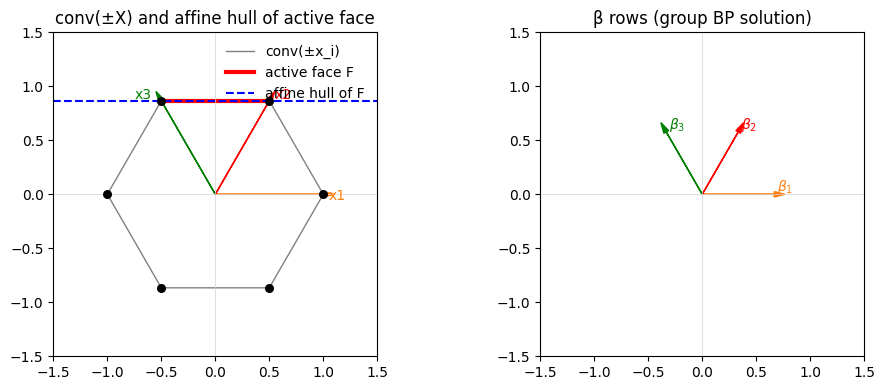

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    """Orthogonally project beta_hat onto {beta : X beta = Y}."""
    R = X @ beta_hat - Y              # residual (n x m)
    M = X @ X.T                       # (n x n)
    # Solve M Lambda = R in least–squares sense
    Lambda, *_ = np.linalg.lstsq(M, R, rcond=None)
    beta_proj = beta_hat - X.T @ Lambda
    Y_proj = X @ beta_proj
    return beta_proj, Y_proj

def group_lasso_norm(beta):
    """Group basis pursuit loss: sum of row 2-norms."""
    return np.linalg.norm(beta, axis=1).sum()

def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters=2500,
    seed=0,
    target=None,
):
    D, P = matrix.shape
    if target is None:
        target = np.eye(D)
    np.random.seed(seed)
    beta = cp.Variable((P, D))
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == target]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.0}
    val = problem.solve(solver=cp.SCS, **scs_opts)
    if val is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0.0
    return beta_sparse

# --- symmetric 3-column example in R^2 ---
x1 = np.array([1.0, 0.0])
x2 = np.array([0.5, np.sqrt(3)/2])
x3 = np.array([-0.5, np.sqrt(3)/2])
X = np.stack([x1, x2, x3], axis=1)   # shape (2,3)
D = 2

# Solve group basis pursuit and project back onto the constraint
beta_putative = group_basis_pursuit(X, eps=1e-16, max_iters=100000,
                                    seed=5, target=np.eye(D))
beta, Y_proj = project_onto_constraint(np.eye(D), X, beta_putative)

print("Group lasso norm:", group_lasso_norm(beta))
print("Row norms:", np.linalg.norm(beta, axis=1))
print("Constraint violation ||I - X beta||:",
      np.linalg.norm(np.eye(D) - X @ beta))

# --- build hexagon conv(±X) and active face / affine hull ---
points = np.concatenate([X, -X], axis=1).T   # (6,2)
angles = np.arctan2(points[:, 1], points[:, 0])
order = np.argsort(angles)
points_ordered = points[order]

# Active face: segment between x2 and x3 for "upward" direction y0 = (0,1)
face_pts = np.vstack([x2, x3])
y0 = np.array([0.0, 1.0])
c = face_pts[0] @ y0          # common y-coordinate
line_x = np.linspace(-1.5, 1.5, 200)
line_y = np.full_like(line_x, c)

# --- plotting ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Left: data vectors + hexagon + active face + affine hull
ax = axes[0]
ax.set_aspect("equal", "box")

# hexagon conv(±x_i)
poly = np.vstack([points_ordered, points_ordered[0]])
ax.plot(poly[:, 0], poly[:, 1], "-", color="gray", linewidth=1,
        label="conv(±x_i)")

# all vertices
ax.scatter(points[:, 0], points[:, 1], color="black", s=30, zorder=3)

# active face (between x2 and x3)
ax.plot(face_pts[:, 0], face_pts[:, 1], color="red", linewidth=3,
        label="active face F")

# affine hull of that face
ax.plot(line_x, line_y, "--", color="blue", linewidth=1.5,
        label="affine hull of F")

# arrows for x1,x2,x3
ax.arrow(0, 0, x1[0], x1[1], head_width=0.05, head_length=0.1,
         fc="tab:orange", ec="tab:orange")
ax.arrow(0, 0, x2[0], x2[1], head_width=0.05, head_length=0.1,
         fc="red", ec="red")
ax.arrow(0, 0, x3[0], x3[1], head_width=0.05, head_length=0.1,
         fc="green", ec="green")
ax.text(x1[0] + 0.05, x1[1] - 0.05, "x1", color="tab:orange")
ax.text(x2[0] + 0.05, x2[1] + 0.02, "x2", color="red")
ax.text(x3[0] - 0.25, x3[1] + 0.02, "x3", color="green")

ax.axhline(0, color="lightgray", linewidth=0.5)
ax.axvline(0, color="lightgray", linewidth=0.5)
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_title("conv(±X) and affine hull of active face")
ax.legend(frameon=False, loc="upper right")

# Right: beta rows as arrows
axb = axes[1]
axb.set_aspect("equal", "box")

colors = ["tab:orange", "red", "green"]
for i in range(3):
    axb.arrow(0, 0, beta[i, 0], beta[i, 1],
              head_width=0.05, head_length=0.1,
              fc=colors[i], ec=colors[i])
    axb.text(beta[i, 0] + 0.03, beta[i, 1] + 0.03,
             fr"$\beta_{i+1}$", color=colors[i])

axb.axhline(0, color="lightgray", linewidth=0.5)
axb.axvline(0, color="lightgray", linewidth=0.5)
axb.set_xlim(-1.5, 1.5)
axb.set_ylim(-1.5, 1.5)
axb.set_title("β rows (group BP solution)")

plt.tight_layout()
plt.show()


Group lasso norm: 2.0
Row norms: [4.60749344e-14 1.00000000e+00 1.00000000e+00]
Constraint violation ||I - X beta||: 1.4825445367816522e-16


/Users/samsonkoelle/miniconda3/envs/isometry_pursuit/lib/python3.11/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


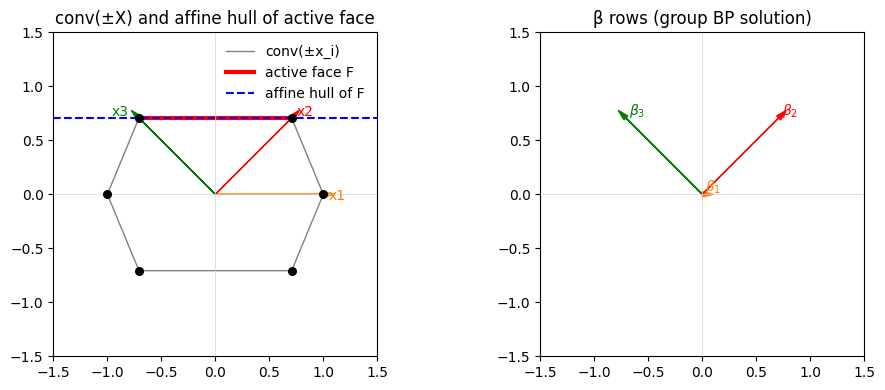

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    """Orthogonally project beta_hat onto {beta : X beta = Y}."""
    R = X @ beta_hat - Y              # residual (n x m)
    M = X @ X.T                       # (n x n)
    # Solve M Lambda = R in least–squares sense
    Lambda, *_ = np.linalg.lstsq(M, R, rcond=None)
    beta_proj = beta_hat - X.T @ Lambda
    Y_proj = X @ beta_proj
    return beta_proj, Y_proj

def group_lasso_norm(beta):
    """Group basis pursuit loss: sum of row 2-norms."""
    return np.linalg.norm(beta, axis=1).sum()

def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters=2500,
    seed=0,
    target=None,
):
    D, P = matrix.shape
    if target is None:
        target = np.eye(D)
    np.random.seed(seed)
    beta = cp.Variable((P, D))
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == target]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.0}
    val = problem.solve(solver=cp.SCS, **scs_opts)
    if val is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0.0
    return beta_sparse

# --- symmetric 3-column example in R^2 ---
x1 = np.array([1.0, 0.0])
x2 = np.array([np.sqrt(2)/2, np.sqrt(2)/2])
x3 = np.array([-np.sqrt(2)/2, np.sqrt(2)/2])
X = np.stack([x1, x2, x3], axis=1)   # shape (2,3)
D = 2

# Solve group basis pursuit and project back onto the constraint
beta_putative = group_basis_pursuit(X, eps=1e-16, max_iters=100000,
                                    seed=5, target=np.eye(D))
beta, Y_proj = project_onto_constraint(np.eye(D), X, beta_putative)

print("Group lasso norm:", group_lasso_norm(beta))
print("Row norms:", np.linalg.norm(beta, axis=1))
print("Constraint violation ||I - X beta||:",
      np.linalg.norm(np.eye(D) - X @ beta))

# --- build hexagon conv(±X) and active face / affine hull ---
points = np.concatenate([X, -X], axis=1).T   # (6,2)
angles = np.arctan2(points[:, 1], points[:, 0])
order = np.argsort(angles)
points_ordered = points[order]

# Active face: segment between x2 and x3 for "upward" direction y0 = (0,1)
face_pts = np.vstack([x2, x3])
y0 = np.array([0.0, 1.0])
c = face_pts[0] @ y0          # common y-coordinate
line_x = np.linspace(-1.5, 1.5, 200)
line_y = np.full_like(line_x, c)

# --- plotting ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Left: data vectors + hexagon + active face + affine hull
ax = axes[0]
ax.set_aspect("equal", "box")

# hexagon conv(±x_i)
poly = np.vstack([points_ordered, points_ordered[0]])
ax.plot(poly[:, 0], poly[:, 1], "-", color="gray", linewidth=1,
        label="conv(±x_i)")

# all vertices
ax.scatter(points[:, 0], points[:, 1], color="black", s=30, zorder=3)

# active face (between x2 and x3)
ax.plot(face_pts[:, 0], face_pts[:, 1], color="red", linewidth=3,
        label="active face F")

# affine hull of that face
ax.plot(line_x, line_y, "--", color="blue", linewidth=1.5,
        label="affine hull of F")

# arrows for x1,x2,x3
ax.arrow(0, 0, x1[0], x1[1], head_width=0.05, head_length=0.1,
         fc="tab:orange", ec="tab:orange")
ax.arrow(0, 0, x2[0], x2[1], head_width=0.05, head_length=0.1,
         fc="red", ec="red")
ax.arrow(0, 0, x3[0], x3[1], head_width=0.05, head_length=0.1,
         fc="green", ec="green")
ax.text(x1[0] + 0.05, x1[1] - 0.05, "x1", color="tab:orange")
ax.text(x2[0] + 0.05, x2[1] + 0.02, "x2", color="red")
ax.text(x3[0] - 0.25, x3[1] + 0.02, "x3", color="green")

ax.axhline(0, color="lightgray", linewidth=0.5)
ax.axvline(0, color="lightgray", linewidth=0.5)
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_title("conv(±X) and affine hull of active face")
ax.legend(frameon=False, loc="upper right")

# Right: beta rows as arrows
axb = axes[1]
axb.set_aspect("equal", "box")

colors = ["tab:orange", "red", "green"]
for i in range(3):
    axb.arrow(0, 0, beta[i, 0], beta[i, 1],
              head_width=0.05, head_length=0.1,
              fc=colors[i], ec=colors[i])
    axb.text(beta[i, 0] + 0.03, beta[i, 1] + 0.03,
             fr"$\beta_{i+1}$", color=colors[i])

axb.axhline(0, color="lightgray", linewidth=0.5)
axb.axvline(0, color="lightgray", linewidth=0.5)
axb.set_xlim(-1.5, 1.5)
axb.set_ylim(-1.5, 1.5)
axb.set_title("β rows (group BP solution)")

plt.tight_layout()
plt.show()


Group lasso norm: 2.309401076758503
Row norms: [1.71582895e-16 1.15470054e+00 1.15470054e+00]
Constraint violation ||I - X beta||: 1.1201425142380136e-16


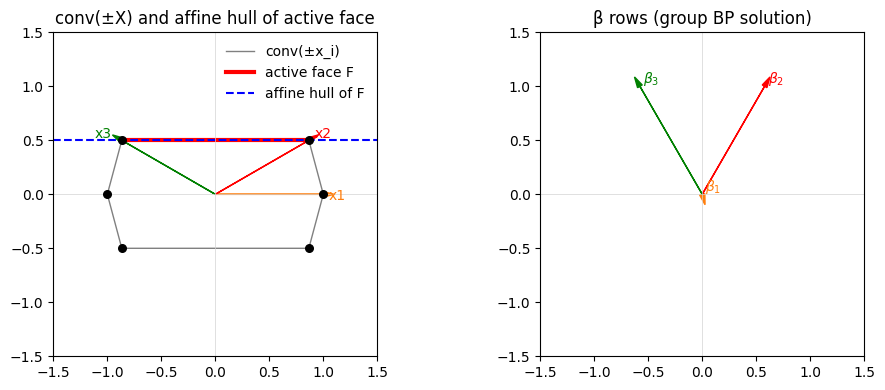

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    """Orthogonally project beta_hat onto {beta : X beta = Y}."""
    R = X @ beta_hat - Y              # residual (n x m)
    M = X @ X.T                       # (n x n)
    # Solve M Lambda = R in least–squares sense
    Lambda, *_ = np.linalg.lstsq(M, R, rcond=None)
    beta_proj = beta_hat - X.T @ Lambda
    Y_proj = X @ beta_proj
    return beta_proj, Y_proj

def group_lasso_norm(beta):
    """Group basis pursuit loss: sum of row 2-norms."""
    return np.linalg.norm(beta, axis=1).sum()

def group_basis_pursuit(
    matrix,
    eps=1e-12,
    threshold=1e-6,
    max_iters=2500,
    seed=0,
    target=None,
):
    D, P = matrix.shape
    if target is None:
        target = np.eye(D)
    np.random.seed(seed)
    beta = cp.Variable((P, D))
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [matrix @ beta == target]
    problem = cp.Problem(objective, constraints)
    scs_opts = {"eps": eps, "max_iters": max_iters, "scale": 10.0}
    val = problem.solve(solver=cp.SCS, **scs_opts)
    if val is np.inf:
        raise ValueError("No solution found")
    beta_optimized = beta.value
    beta_sparse = beta_optimized.copy()
    beta_sparse[np.abs(beta_sparse) < threshold] = 0.0
    return beta_sparse

# --- symmetric 3-column example in R^2 ---
x1 = np.array([1.0, 0.0])
x2 = np.array([np.sqrt(3)/2, 1/2])
x3 = np.array([-np.sqrt(3)/2, 1/2])
X = np.stack([x1, x2, x3], axis=1)   # shape (2,3)
D = 2

# Solve group basis pursuit and project back onto the constraint
beta_putative = group_basis_pursuit(X, eps=1e-16, max_iters=100000,
                                    seed=5, target=np.eye(D))
beta, Y_proj = project_onto_constraint(np.eye(D), X, beta_putative)

print("Group lasso norm:", group_lasso_norm(beta))
print("Row norms:", np.linalg.norm(beta, axis=1))
print("Constraint violation ||I - X beta||:",
      np.linalg.norm(np.eye(D) - X @ beta))

# --- build hexagon conv(±X) and active face / affine hull ---
points = np.concatenate([X, -X], axis=1).T   # (6,2)
angles = np.arctan2(points[:, 1], points[:, 0])
order = np.argsort(angles)
points_ordered = points[order]

# Active face: segment between x2 and x3 for "upward" direction y0 = (0,1)
face_pts = np.vstack([x2, x3])
y0 = np.array([0.0, 1.0])
c = face_pts[0] @ y0          # common y-coordinate
line_x = np.linspace(-1.5, 1.5, 200)
line_y = np.full_like(line_x, c)

# --- plotting ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Left: data vectors + hexagon + active face + affine hull
ax = axes[0]
ax.set_aspect("equal", "box")

# hexagon conv(±x_i)
poly = np.vstack([points_ordered, points_ordered[0]])
ax.plot(poly[:, 0], poly[:, 1], "-", color="gray", linewidth=1,
        label="conv(±x_i)")

# all vertices
ax.scatter(points[:, 0], points[:, 1], color="black", s=30, zorder=3)

# active face (between x2 and x3)
ax.plot(face_pts[:, 0], face_pts[:, 1], color="red", linewidth=3,
        label="active face F")

# affine hull of that face
ax.plot(line_x, line_y, "--", color="blue", linewidth=1.5,
        label="affine hull of F")

# arrows for x1,x2,x3
ax.arrow(0, 0, x1[0], x1[1], head_width=0.05, head_length=0.1,
         fc="tab:orange", ec="tab:orange")
ax.arrow(0, 0, x2[0], x2[1], head_width=0.05, head_length=0.1,
         fc="red", ec="red")
ax.arrow(0, 0, x3[0], x3[1], head_width=0.05, head_length=0.1,
         fc="green", ec="green")
ax.text(x1[0] + 0.05, x1[1] - 0.05, "x1", color="tab:orange")
ax.text(x2[0] + 0.05, x2[1] + 0.02, "x2", color="red")
ax.text(x3[0] - 0.25, x3[1] + 0.02, "x3", color="green")

ax.axhline(0, color="lightgray", linewidth=0.5)
ax.axvline(0, color="lightgray", linewidth=0.5)
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_title("conv(±X) and affine hull of active face")
ax.legend(frameon=False, loc="upper right")

# Right: beta rows as arrows
axb = axes[1]
axb.set_aspect("equal", "box")

colors = ["tab:orange", "red", "green"]
for i in range(3):
    axb.arrow(0, 0, beta[i, 0], beta[i, 1],
              head_width=0.05, head_length=0.1,
              fc=colors[i], ec=colors[i])
    axb.text(beta[i, 0] + 0.03, beta[i, 1] + 0.03,
             fr"$\beta_{i+1}$", color=colors[i])

axb.axhline(0, color="lightgray", linewidth=0.5)
axb.axvline(0, color="lightgray", linewidth=0.5)
axb.set_xlim(-1.5, 1.5)
axb.set_ylim(-1.5, 1.5)
axb.set_title("β rows (group BP solution)")

plt.tight_layout()
plt.show()


Group lasso norm: 2.309401076758503
Row norms: [4.44089210e-17 1.15470054e+00 1.15470054e+00]
Constraint violation: 0.0

Dual block norms |X^T Y*|: [0.57735027 1.         1.        ]
Active groups: [False  True  True]


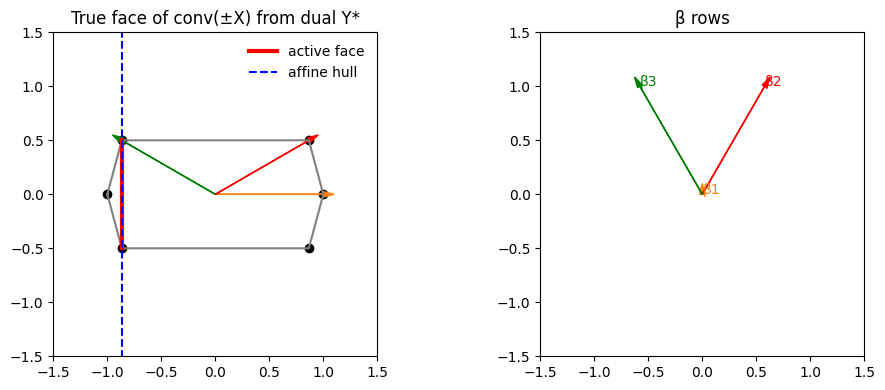

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp

def project_onto_constraint(Y, X, beta_hat):
    R = X @ beta_hat - Y
    M = X @ X.T
    Lambda, *_ = np.linalg.lstsq(M, R, rcond=None)
    beta_proj = beta_hat - X.T @ Lambda
    Y_proj = X @ beta_proj
    return beta_proj, Y_proj

def group_lasso_norm(beta):
    return np.linalg.norm(beta, axis=1).sum()

def group_basis_pursuit(
    X, eps=1e-12, threshold=1e-6, max_iters=2500, seed=0, target=None
):
    D, P = X.shape
    if target is None:
        target = np.eye(D)

    beta = cp.Variable((P, D))
    objective = cp.Minimize(cp.sum(cp.norm(beta, axis=1)))
    constraints = [X @ beta == target]

    problem = cp.Problem(objective, constraints)
    val = problem.solve(solver=cp.SCS,
                        eps=eps,
                        max_iters=max_iters,
                        scale=10.0)

    beta_value = beta.value
    beta_value[np.abs(beta_value) < threshold] = 0

    # Extract dual variable from equality constraint
    Y_star = constraints[0].dual_value   # shape (D, D)
    return beta_value, Y_star

# === Your “learn something” X ===
x1 = np.array([1.0, 0.0])
x2 = np.array([np.sqrt(3)/2, 1/2])
x3 = np.array([-np.sqrt(3)/2, 1/2])

X = np.stack([x1, x2, x3], axis=1)  # (2,3)
D = 2

beta, Y_star = group_basis_pursuit(X, eps=1e-12, max_iters=200000, target=np.eye(D))

# Project back onto feasibility
beta_proj, _ = project_onto_constraint(np.eye(D), X, beta)

print("Group lasso norm:", group_lasso_norm(beta_proj))
print("Row norms:", np.linalg.norm(beta_proj, axis=1))
print("Constraint violation:", np.linalg.norm(np.eye(D) - X @ beta_proj))

# === Compute true active face ===
# Compute |X^T Y_star|
XTYS = np.linalg.norm(X.T @ Y_star, axis=1)   # group-lasso dual blocks are 2D
active = np.isclose(XTYS, 1.0, atol=1e-3)

print("\nDual block norms |X^T Y*|:", XTYS)
print("Active groups:", active)

# Select the *sign-corrected* active vertices
sig = np.sign((X.T @ Y_star)[:,0] + 1e-12)   # just pick sign from first component
active_vectors = (sig[:, None] * X.T)[active]

# Build polytope conv(±X)
points = np.concatenate([X, -X], axis=1).T
angles = np.arctan2(points[:,1], points[:,0])
points_ordered = points[np.argsort(angles)]

# === Plot ===
fig, axes = plt.subplots(1, 2, figsize=(10,4))

# Left: polytope + true active face + affine hull
ax = axes[0]
ax.set_aspect("equal")

# polytope
poly = np.vstack([points_ordered, points_ordered[0]])
ax.plot(poly[:,0], poly[:,1], '-', color='gray')

# vertices
ax.scatter(points[:,0], points[:,1], color='black')

# plot active face (possibly 1 point!)
if len(active_vectors) >= 2:
    ax.plot(active_vectors[:,0], active_vectors[:,1],
            color='red', linewidth=3, label='active face')
else:
    ax.scatter(active_vectors[:,0], active_vectors[:,1],
               color='red', s=80, label='active vertex')

# affine hull (if >=2 points)
if len(active_vectors) >= 2:
    v1, v2 = active_vectors[0], active_vectors[1]
    # supporting line passing through v1, v2
    t = np.linspace(-2, 2, 100)
    direction = v2 - v1
    line = v1 + np.outer(t, direction)
    ax.plot(line[:,0], line[:,1], '--', color='blue', label='affine hull')

# plot columns
colors = ['tab:orange', 'red', 'green']
for x, c in zip([x1,x2,x3], colors):
    ax.arrow(0,0, x[0],x[1], fc=c, ec=c,
             head_width=0.05, head_length=0.1)

ax.set_xlim(-1.5,1.5)
ax.set_ylim(-1.5,1.5)
ax.set_title("True face of conv(±X) from dual Y*")
ax.legend(frameon=False)

# Right: β rows
axb = axes[1]
axb.set_aspect("equal")
for i in range(3):
    axb.arrow(0,0, beta_proj[i,0], beta_proj[i,1],
              fc=colors[i], ec=colors[i],
              head_width=0.05, head_length=0.1)
    axb.text(beta_proj[i,0], beta_proj[i,1],
             f"β{i+1}", color=colors[i])
axb.set_xlim(-1.5,1.5)
axb.set_ylim(-1.5,1.5)
axb.set_title("β rows")

plt.tight_layout()
plt.show()
